In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='darkgrid')

In [2]:
data = pd.read_csv('data/train.csv', index_col='Id')
data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 1 to 1460
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   str    
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   str    
 5   Alley          91 non-null     str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

More than half of the columns are non-numeric.

Number of columns with nulls: 19


,nulls,dtype
Electrical,1,str
MasVnrArea,8,float64
BsmtCond,37,str
BsmtFinType1,37,str
BsmtQual,37,str
BsmtExposure,38,str
BsmtFinType2,38,str
GarageType,81,str
GarageQual,81,str
GarageFinish,81,str


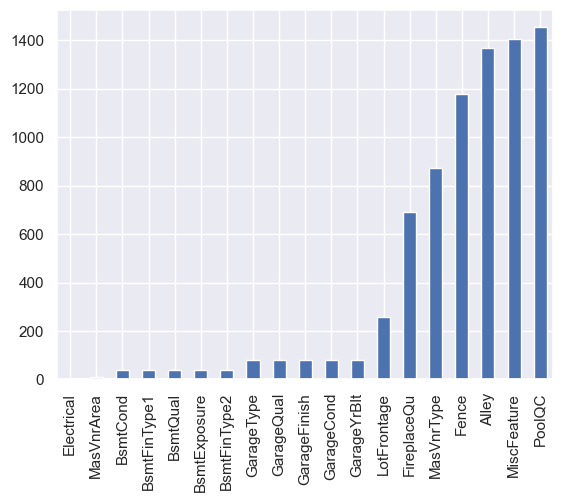

In [4]:
has_null_cols = pd.DataFrame({
    'nulls': data.isnull().sum(),
    'dtype': data.dtypes
}).query('nulls > 0')

print(f'Number of columns with nulls: {len(has_null_cols)}')
has_null_cols['nulls'].sort_values().plot.bar()
has_null_cols.sort_values(by='nulls')

5 features have over 50% null values

## Target distribution

Let`s see the target distribution

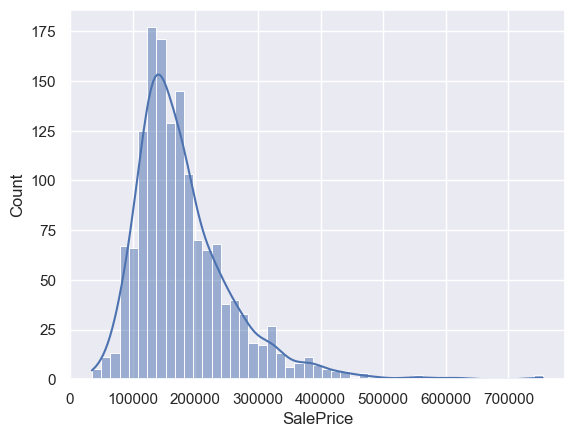

In [5]:
sns.histplot(data['SalePrice'], kde=True)
None

Logarithm of the target

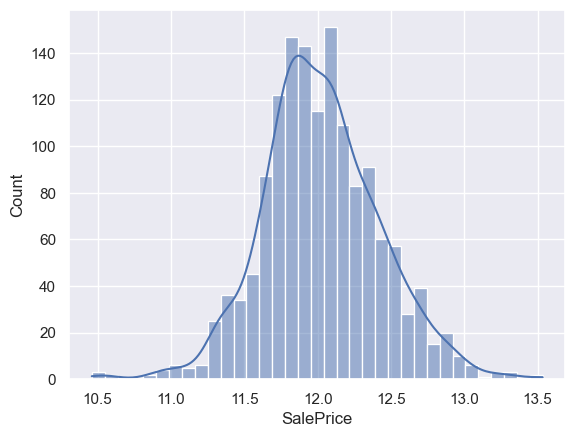

In [6]:
sns.histplot(np.log(data['SalePrice']), kde=True)
None

This one looks much more like a normal distribution

## Categorical variables

Number of unique values in each categorical feature

In [7]:
data.select_dtypes(include=str).nunique().sort_values(ascending=False)


Neighborhood     25
Exterior2nd      16
Exterior1st      15
Condition1        9
SaleType          9
HouseStyle        8
RoofMatl          8
Condition2        8
Functional        7
BsmtFinType2      6
RoofStyle         6
BsmtFinType1      6
SaleCondition     6
Heating           6
Foundation        6
GarageType        6
ExterCond         5
LotConfig         5
MSZoning          5
GarageCond        5
GarageQual        5
HeatingQC         5
Electrical        5
BldgType          5
FireplaceQu       5
LandContour       4
LotShape          4
KitchenQual       4
MiscFeature       4
Fence             4
BsmtCond          4
ExterQual         4
BsmtExposure      4
BsmtQual          4
LandSlope         3
PoolQC            3
GarageFinish      3
PavedDrive        3
MasVnrType        3
Utilities         2
Alley             2
Street            2
CentralAir        2
dtype: int64

Let's explore `Neighborhood`, `ExterQual`, `KitchenQual` and `HouseStyle`

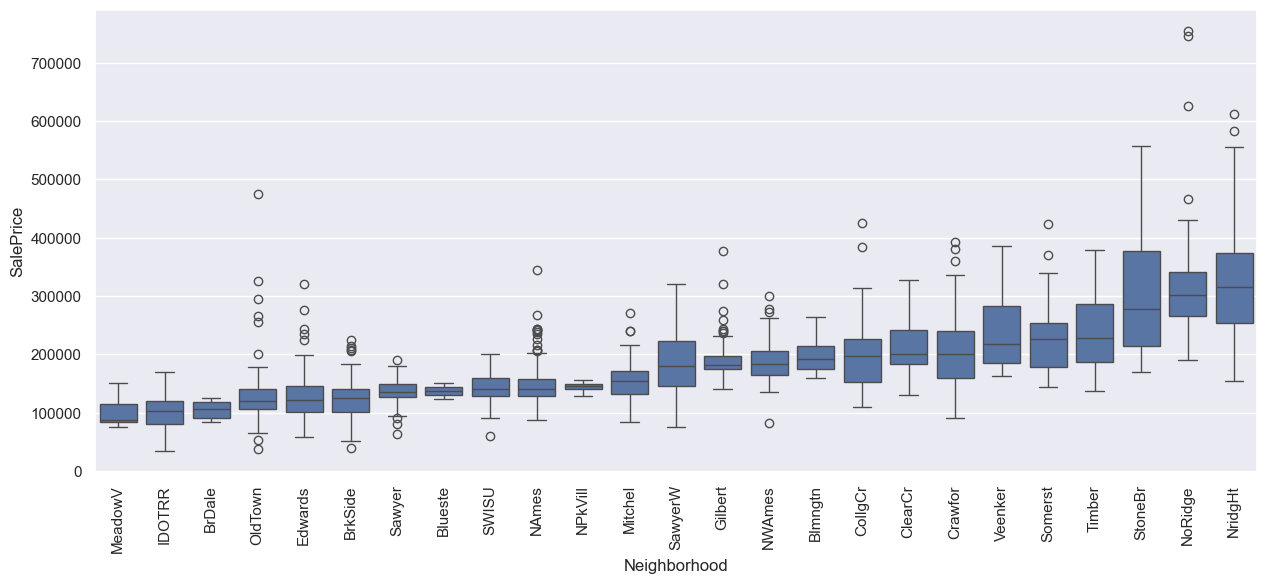

In [8]:
order = data.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(15, 6))
sns.boxplot(data=data, x="Neighborhood", y="SalePrice", order=order)
plt.xticks(rotation=90)
plt.show()

Three categories in `Neighborhood` have a much higher median `SalePrice`

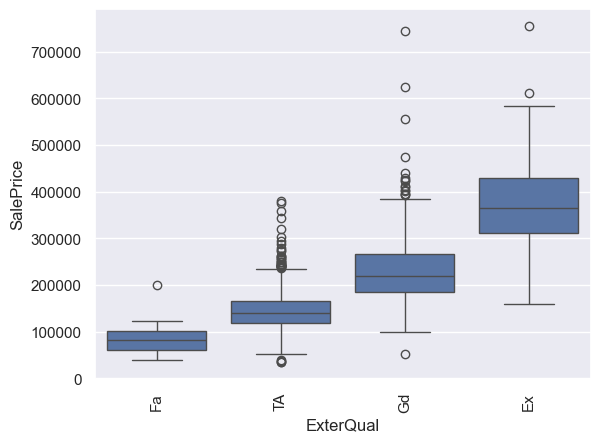

In [9]:
order = data.groupby("ExterQual")["SalePrice"].median().sort_values().index

sns.boxplot(data=data, x="ExterQual", y="SalePrice", order=order)
plt.xticks(rotation=90)
plt.show()


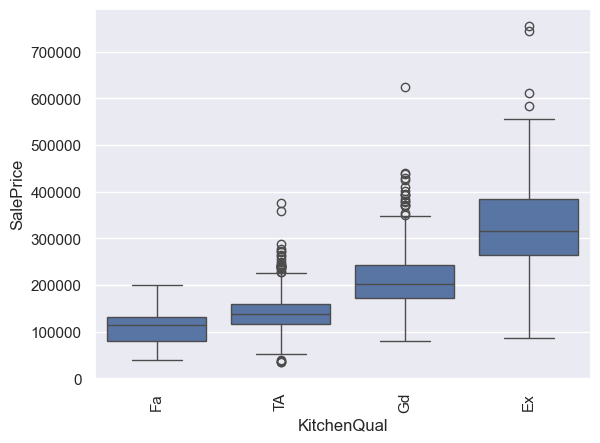

In [10]:
order = data.groupby("KitchenQual")["SalePrice"].median().sort_values().index

sns.boxplot(data=data, x="KitchenQual", y="SalePrice", order=order)
plt.xticks(rotation=90)
plt.show()

`ExterQual` and `KitchenQual` categories have an obvious order. Ordinal encoding may be appropriate

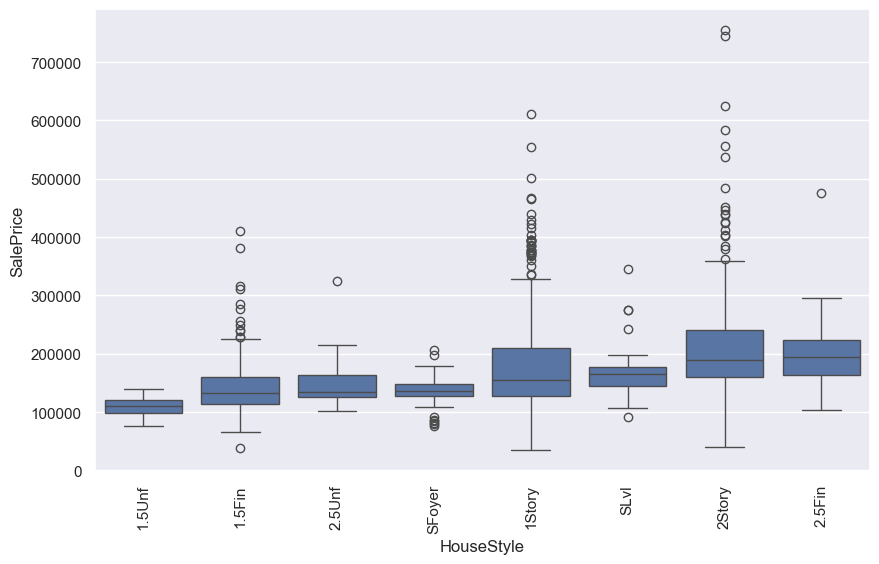

In [11]:
order = data.groupby("HouseStyle")["SalePrice"].median().sort_values().index

plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x="HouseStyle", y="SalePrice", order=order)
plt.xticks(rotation=90)
plt.show()


Two `HouseStyle` categories have a higher mean `SalePrice`

## Numeric Variables

### Correlations between numeric variables and the target

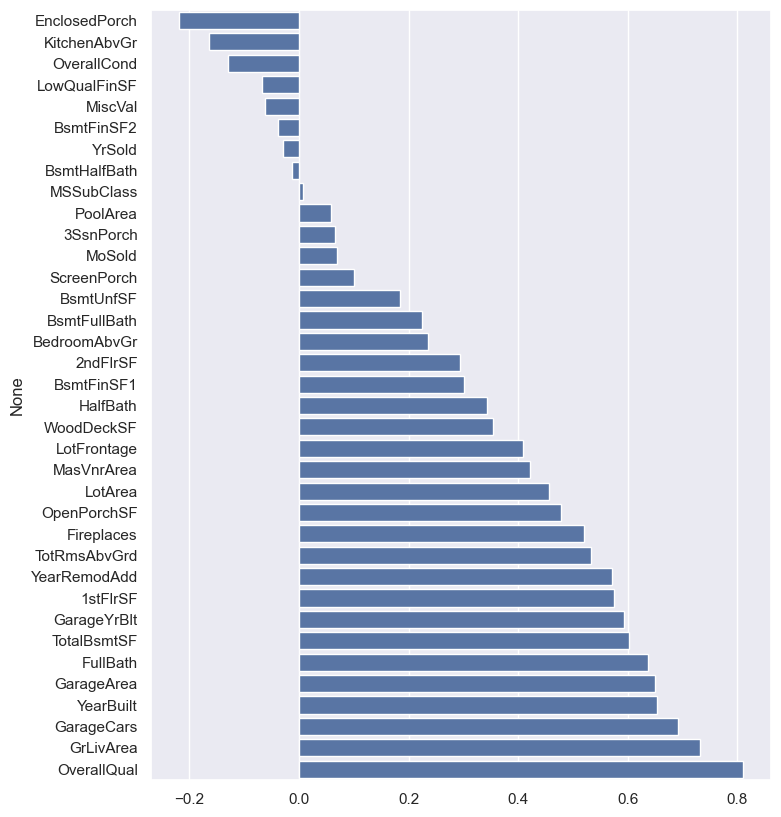

In [12]:
corr = (
    data.select_dtypes(include=np.number)
    .corr(method="spearman")["SalePrice"]
    .drop("SalePrice")
    .sort_values()
)

plt.figure(figsize=(8, 10))
sns.barplot(x=corr.values, y=corr.index)
None

`OverallQual`, `GrLivArea` and `GarageCars` have a very strong correlation with the target `SalePrice`

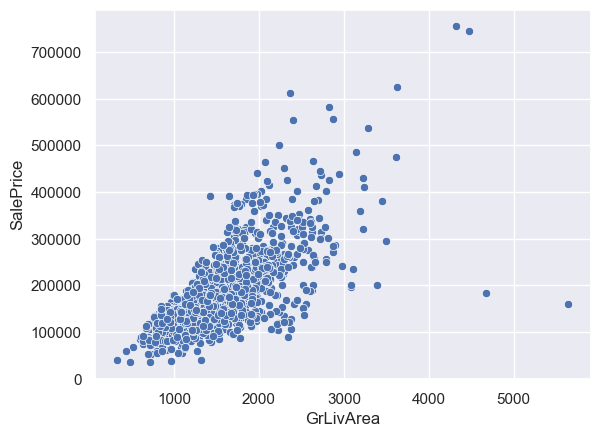

In [13]:
sns.scatterplot(data=data, x="GrLivArea", y="SalePrice")
None

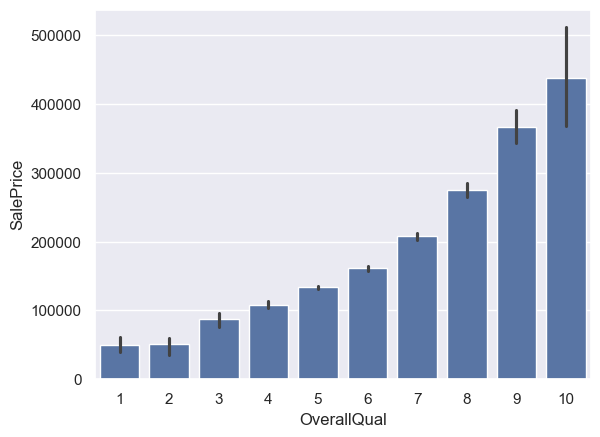

In [14]:
sns.barplot(data=data, x="OverallQual", y="SalePrice")
None

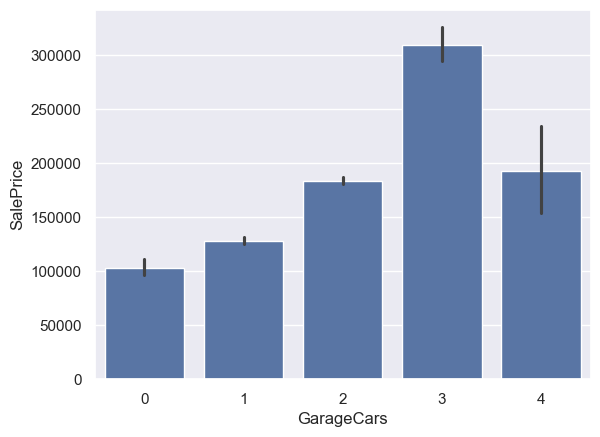

In [15]:
sns.barplot(data=data, x="GarageCars", y="SalePrice")
None

### Correlations between numeric variables

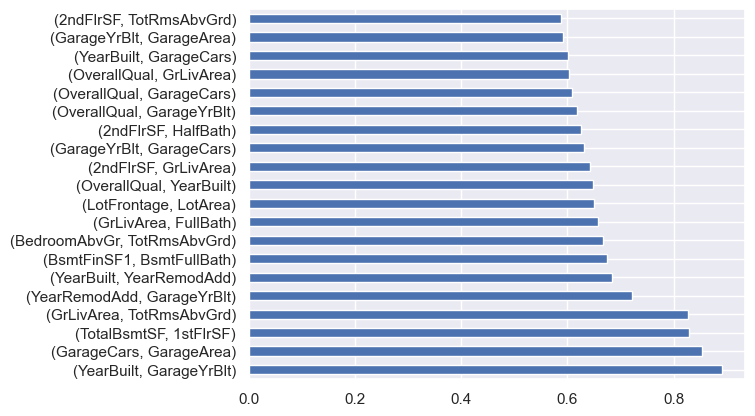

In [16]:
corr = data.drop(columns="SalePrice").corr(
    method="spearman", numeric_only=True
)

mask = np.triu(np.ones(corr.shape), k=1).astype(bool)

top_corr = (
    corr.where(mask)
    .stack()
    .sort_values(key=abs, ascending=False)
    .head(20)
)

top_corr.plot.barh()
None

Strongly correlated features probably need to be removed

## Checking constant columns

In [17]:
dominance = data.apply(
    lambda col: col.value_counts(normalize=True, dropna=True).max()
)

near_constant = dominance[dominance > 0.95].sort_values(ascending=False)
near_constant

Utilities       0.999315
Street          0.995890
PoolArea        0.995205
Condition2      0.989726
3SsnPorch       0.983562
RoofMatl        0.982192
LowQualFinSF    0.982192
Heating         0.978082
MiscVal         0.964384
GarageCond      0.961566
KitchenAbvGr    0.953425
GarageQual      0.950689
dtype: float64

Some columns have almost the same value for all samples

In [18]:
data['Utilities'].value_counts()

Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

In [19]:
data['Street'].value_counts()

Street
Pave    1454
Grvl       6
Name: count, dtype: int64

In [20]:
data['PoolArea'].value_counts()

PoolArea
0      1453
512       1
648       1
576       1
555       1
480       1
519       1
738       1
Name: count, dtype: int64

Almost all samples have the same `Utilities`, `Street` and `PoolArea` values